In [ ]:
project_title = "Identifying Loss-Making Products Using Sales Data"

print("Project Title:", project_title)

Project Title: Identifying Loss-Making Products Using Sales Data


In [ ]:
problem_statement = """
Businesses may generate high sales but still experience
losses due to discounts, product costs, or poor sales
performance.

This project aims to analyse sales data using Python
to identify loss-making products and understand
the factors affecting profitability.
"""

print("PROBLEM STATEMENT")
print(problem_statement)

PROBLEM STATEMENT

Businesses may generate high sales but still experience
losses due to discounts, product costs, or poor sales
performance.

This project aims to analyse sales data using Python
to identify loss-making products and understand
the factors affecting profitability.



In [ ]:
objectives = [
    "Identify loss-making products",
    "Analyse product-wise sales and profit",
    "Understand the impact of discounts on profit",
    "Compare profit across product categories",
    "Suggest ways to improve business profitability"
]

print("PROJECT OBJECTIVES\n")

for i, objective in enumerate(objectives, start=1):
    print(f"{i}. {objective}")

PROJECT OBJECTIVES

1. Identify loss-making products
2. Analyse product-wise sales and profit
3. Understand the impact of discounts on profit
4. Compare profit across product categories
5. Suggest ways to improve business profitability


In [ ]:
success_metrics = {
    "Total Sales": "Calculate overall sales",
    "Total Profit": "Calculate overall profit or loss",
    "Profit Margin": "Measure profit as a percentage of sales",
    "Loss-Making Products": "Identify products with negative profit",
    "Most Profitable Products": "Identify products generating high profit"
}

print("PROJECT SUCCESS METRICS\n")

for metric, meaning in success_metrics.items():
    print(f"{metric}: {meaning}")

PROJECT SUCCESS METRICS

Total Sales: Calculate overall sales
Total Profit: Calculate overall profit or loss
Profit Margin: Measure profit as a percentage of sales
Loss-Making Products: Identify products with negative profit
Most Profitable Products: Identify products generating high profit


In [7]:
import os

files = os.listdir("/content")

print("Uploaded files:")

for file in files:
    print(file)

Uploaded files:
.config
Sample - Superstore.csv
sample_data


In [8]:
import pandas as pd

df = pd.read_csv("/content/Sample - Superstore.csv", encoding="latin1")

print(df.head())


   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
1       2  CA-2016-152156   11/8/2016  11/11/2016    Second Class    CG-12520   
2       3  CA-2016-138688   6/12/2016   6/16/2016    Second Class    DV-13045   
3       4  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   
4       5  US-2015-108966  10/11/2015  10/18/2015  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID         Category Sub-Category  \
0       42420   Sout

In [9]:
print("Dataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape:
(9994, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [10]:
# Check dataset information
df.info()

# Check missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [11]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: 0


In [12]:
# Convert date columns to datetime format
df["Order Date"] = pd.to_datetime(
    df["Order Date"], format="mixed"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], format="mixed"
)

# Check the updated data types
print(df[["Order Date", "Ship Date"]].dtypes)

# Display first 5 dates
print(df[["Order Date", "Ship Date"]].head())

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object
  Order Date  Ship Date
0 2016-11-08 2016-11-11
1 2016-11-08 2016-11-11
2 2016-06-12 2016-06-16
3 2015-10-11 2015-10-18
4 2015-10-11 2015-10-18


In [13]:
# Summary statistics for numerical columns
print(df[["Sales", "Profit", "Discount", "Quantity"]].describe())

              Sales       Profit     Discount     Quantity
count   9994.000000  9994.000000  9994.000000  9994.000000
mean     229.858001    28.656896     0.156203     3.789574
std      623.245101   234.260108     0.206452     2.225110
min        0.444000 -6599.978000     0.000000     1.000000
25%       17.280000     1.728750     0.000000     2.000000
50%       54.490000     8.666500     0.200000     3.000000
75%      209.940000    29.364000     0.200000     5.000000
max    22638.480000  8399.976000     0.800000    14.000000


In [14]:
# Calculate overall business performance

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()

profit_margin = (total_profit / total_sales) * 100

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Quantity Sold:", total_quantity)
print("Profit Margin (%):", round(profit_margin, 2))

Total Sales: 2297200.86
Total Profit: 286397.02
Total Quantity Sold: 37873
Profit Margin (%): 12.47


In [15]:
# Calculate profit by category

category_profit = df.groupby("Category")["Profit"].sum()

print("Category-wise Profit:\n")
print(category_profit.sort_values(ascending=False))

Category-wise Profit:

Category
Technology         145454.9481
Office Supplies    122490.8008
Furniture           18451.2728
Name: Profit, dtype: float64


In [16]:
# Calculate profit by sub-category

subcategory_profit = (
    df.groupby("Sub-Category")["Profit"]
    .sum()
    .sort_values()
)

print("Sub-Category-wise Profit:\n")
print(subcategory_profit)

Sub-Category-wise Profit:

Sub-Category
Tables        -17725.4811
Bookcases      -3472.5560
Supplies       -1189.0995
Fasteners        949.5182
Machines        3384.7569
Labels          5546.2540
Art             6527.7870
Envelopes       6964.1767
Furnishings    13059.1436
Appliances     18138.0054
Storage        21278.8264
Chairs         26590.1663
Binders        30221.7633
Paper          34053.5693
Accessories    41936.6357
Phones         44515.7306
Copiers        55617.8249
Name: Profit, dtype: float64


In [17]:
# Identify loss-making sub-categories

loss_subcategories = subcategory_profit[
    subcategory_profit < 0
]

print("Loss-Making Sub-Categories:\n")
print(loss_subcategories)

print(
    "\nTotal loss-making sub-categories:",
    len(loss_subcategories)
)

Loss-Making Sub-Categories:

Sub-Category
Tables      -17725.4811
Bookcases    -3472.5560
Supplies     -1189.0995
Name: Profit, dtype: float64

Total loss-making sub-categories: 3


In [18]:
# Calculate total profit for each product

product_profit = (
    df.groupby("Product Name")["Profit"]
    .sum()
    .sort_values()
)

# Select products with negative total profit

loss_products = product_profit[
    product_profit < 0
]

print("Total Loss-Making Products:", len(loss_products))

print("\nTop 10 Loss-Making Products:")
print(loss_products.head(10))

Total Loss-Making Products: 301

Top 10 Loss-Making Products:
Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                           -4589.9730
Cubify CubeX 3D Printer Triple Head Print                           -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.1156
Bush Advantage Collection Racetrack Conference Table                -1934.3976
GBC DocuBind P400 Electric Binding System                           -1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.0784
Martin Yale Chadless Opener Electric Letter Opener                  -1299.1836
Balt Solid Wood Round Tables                                        -1201.0581
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.4375
Name: Profit, dtype: float64


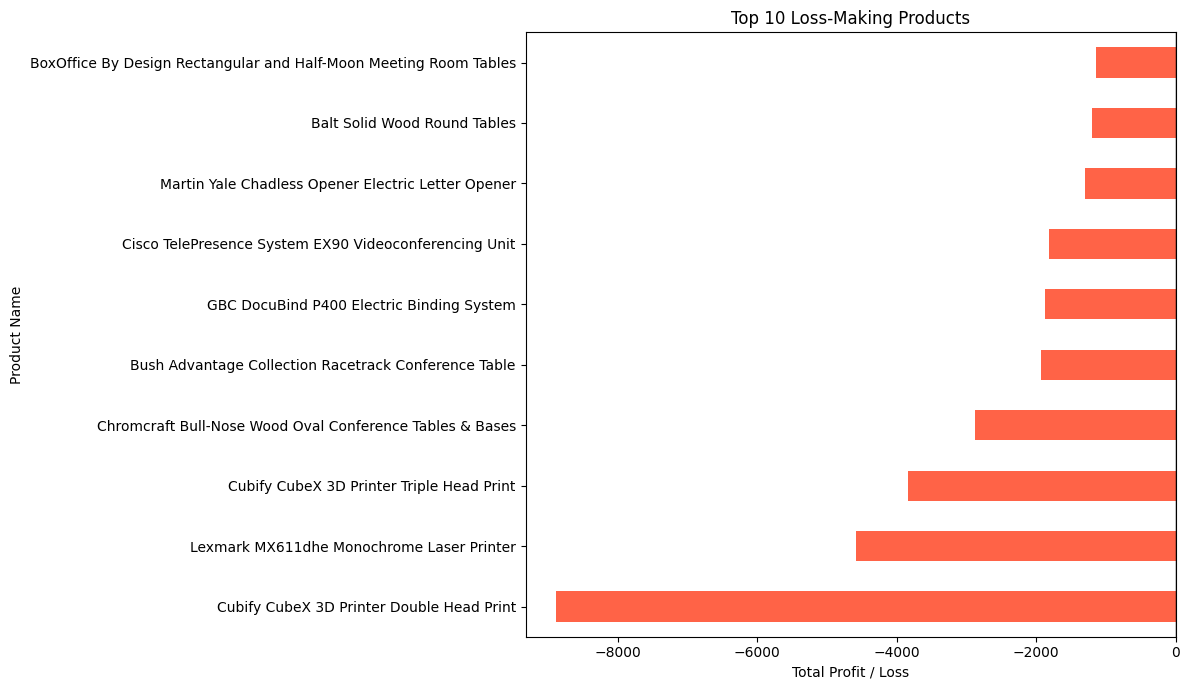

In [19]:
import matplotlib.pyplot as plt

top_10_loss = loss_products.head(10).sort_values()

plt.figure(figsize=(12, 7))

top_10_loss.plot(kind="barh", color="tomato")

plt.title("Top 10 Loss-Making Products")
plt.xlabel("Total Profit / Loss")
plt.ylabel("Product Name")
plt.axvline(x=0, color="black", linewidth=1)

plt.tight_layout()
plt.show()

In [20]:
print("PROJECT FINDINGS SUMMARY")
print("-" * 35)

print("Total Records:", len(df))
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))

print(
    "Profit Margin (%):",
    round(df["Profit"].sum() / df["Sales"].sum() * 100, 2)
)

print("Loss-Making Products:", len(loss_products))

print(
    "Worst Performing Product:",
    loss_products.index[0]
)

print(
    "Highest Product Loss:",
    round(loss_products.iloc[0], 2)
)

print(
    "Loss-Making Sub-Categories:",
    len(loss_subcategories)
)

PROJECT FINDINGS SUMMARY
-----------------------------------
Total Records: 9994
Total Sales: 2297200.86
Total Profit: 286397.02
Profit Margin (%): 12.47
Loss-Making Products: 301
Worst Performing Product: Cubify CubeX 3D Printer Double Head Print
Highest Product Loss: -8879.97
Loss-Making Sub-Categories: 3


In [21]:
# Day 3 - Step 1: Explore product categories

categories = df["Category"].unique()

print("Product Categories:")

for category in categories:
    print(category)

print("\nTotal Categories:", df["Category"].nunique())

Product Categories:
Furniture
Office Supplies
Technology

Total Categories: 3


In [22]:
# Day 3 - Step 2: Explore sub-categories

subcategories = df["Sub-Category"].unique()

print("Product Sub-Categories:\n")

for subcategory in subcategories:
    print(subcategory)

print("\nTotal Sub-Categories:", df["Sub-Category"].nunique())

Product Sub-Categories:

Bookcases
Chairs
Labels
Tables
Storage
Furnishings
Art
Phones
Binders
Appliances
Paper
Accessories
Envelopes
Fasteners
Supplies
Machines
Copiers

Total Sub-Categories: 17


In [23]:
# Day 3 - Step 3: Explore regions

regions = df["Region"].unique()

print("Available Regions:\n")

for region in regions:
    print(region)

print("\nTotal Regions:", df["Region"].nunique())

Available Regions:

South
West
Central
East

Total Regions: 4


In [24]:
# Day 3 - Step 4: Region-wise Sales Analysis

region_sales = (
    df.groupby("Region")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Region-wise Total Sales:\n")
print(region_sales)

Region-wise Total Sales:

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


In [25]:
# Day 3 - Step 5: Region-wise Profit Analysis

region_profit = (
    df.groupby("Region")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print("Region-wise Total Profit:\n")
print(region_profit)

Region-wise Total Profit:

Region
West       108418.4489
East        91522.7800
South       46749.4303
Central     39706.3625
Name: Profit, dtype: float64


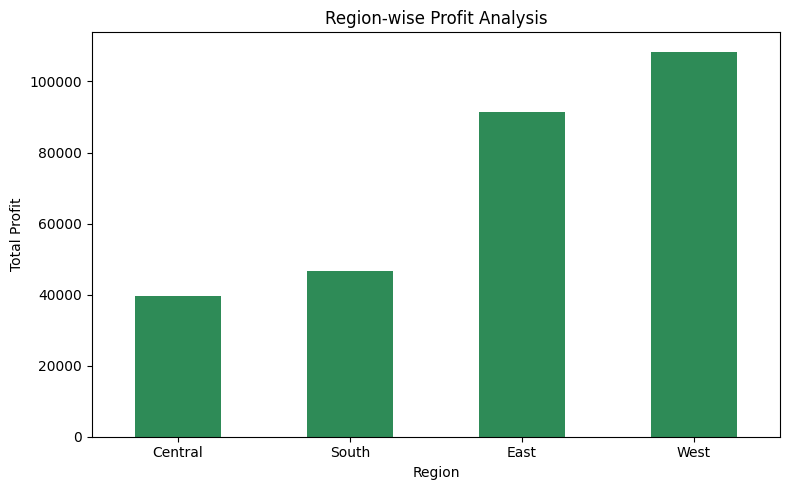

In [26]:
import matplotlib.pyplot as plt

region_profit.sort_values().plot(
    kind="bar",
    color="seagreen",
    figsize=(8, 5)
)

plt.title("Region-wise Profit Analysis")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [27]:
# Day 3 - Step 7: Segment-wise Sales Analysis

segment_sales = (
    df.groupby("Segment")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

print("Segment-wise Total Sales:\n")
print(segment_sales)

Segment-wise Total Sales:

Segment
Consumer       1.161401e+06
Corporate      7.061464e+05
Home Office    4.296531e+05
Name: Sales, dtype: float64


In [28]:
# Day 3 - Step 8: Segment-wise Profit Analysis

segment_profit = (
    df.groupby("Segment")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

print("Segment-wise Total Profit:\n")
print(segment_profit.round(2))

Segment-wise Total Profit:

Segment
Consumer       134119.21
Corporate       91979.13
Home Office     60298.68
Name: Profit, dtype: float64


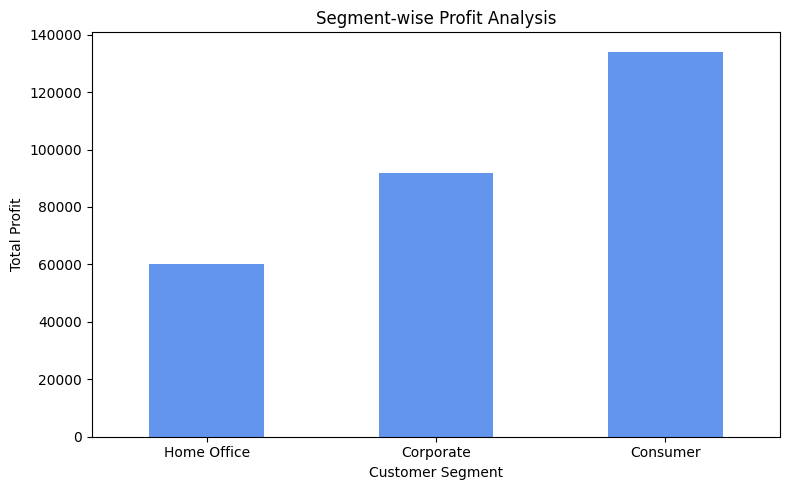

In [29]:
import matplotlib.pyplot as plt

segment_profit.sort_values().plot(
    kind="bar",
    color="cornflowerblue",
    figsize=(8, 5)
)

plt.title("Segment-wise Profit Analysis")
plt.xlabel("Customer Segment")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [30]:
# Day 3 - Step 10: Discount-wise Profit Analysis

discount_profit = (
    df.groupby("Discount")["Profit"]
    .agg(["sum", "mean", "count"])
)

discount_profit.columns = [
    "Total Profit",
    "Average Profit",
    "Number of Records"
]

print("Discount-wise Profit Analysis:\n")
print(discount_profit.round(2))

Discount-wise Profit Analysis:

          Total Profit  Average Profit  Number of Records
Discount                                                 
0.00         320987.60           66.90               4798
0.10           9029.18           96.06                 94
0.15           1418.99           27.29                 52
0.20          90337.31           24.70               3657
0.30         -10369.28          -45.68                227
0.32          -2391.14          -88.56                 27
0.40         -23057.05         -111.93                206
0.45          -2493.11         -226.65                 11
0.50         -20506.43         -310.70                 66
0.60          -5944.66          -43.08                138
0.70         -40075.36          -95.87                418
0.80         -30539.04         -101.80                300


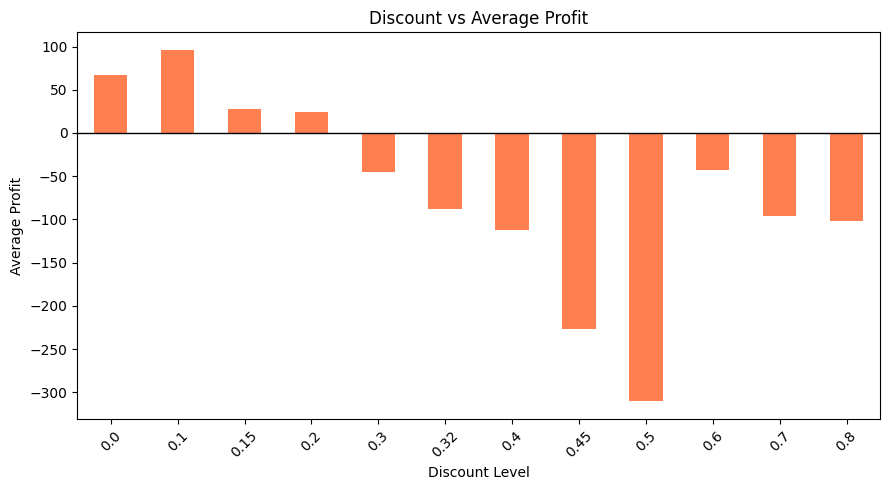

In [31]:
import matplotlib.pyplot as plt

discount_profit["Average Profit"].plot(
    kind="bar",
    color="coral",
    figsize=(9, 5)
)

plt.title("Discount vs Average Profit")
plt.xlabel("Discount Level")
plt.ylabel("Average Profit")
plt.axhline(y=0, color="black", linewidth=1)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
# Day 3 - Step 12: Category Performance

category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Average_Profit=("Profit", "mean"),
    Total_Quantity=("Quantity", "sum")
)

print("Category Performance Analysis:\n")
print(category_analysis.round(2))

Category Performance Analysis:

                 Total_Sales  Total_Profit  Average_Profit  Total_Quantity
Category                                                                  
Furniture          741999.80      18451.27            8.70            8028
Office Supplies    719047.03     122490.80           20.33           22906
Technology         836154.03     145454.95           78.75            6939


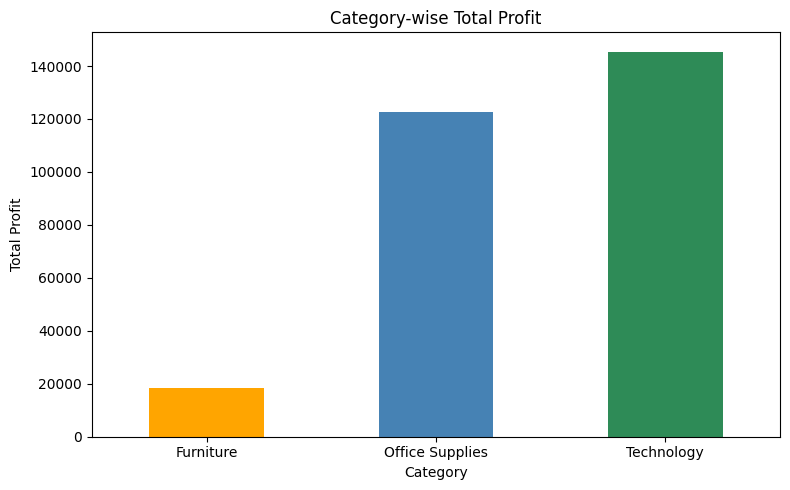

In [33]:
import matplotlib.pyplot as plt

category_analysis["Total_Profit"].plot(
    kind="bar",
    color=["orange", "steelblue", "seagreen"],
    figsize=(8, 5)
)

plt.title("Category-wise Total Profit")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [34]:
# Day 3 - Step 14: Extract Year and Month

df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month

print("Order Date, Year and Month:")
print(df[["Order Date", "Year", "Month"]].head())

print("\nYears in Dataset:")
print(sorted(df["Year"].unique()))

Order Date, Year and Month:
  Order Date  Year  Month
0 2016-11-08  2016     11
1 2016-11-08  2016     11
2 2016-06-12  2016      6
3 2015-10-11  2015     10
4 2015-10-11  2015     10

Years in Dataset:
[np.int32(2014), np.int32(2015), np.int32(2016), np.int32(2017)]


In [35]:
# Day 3 - Step 15: Year-wise Sales Analysis

yearly_sales = (
    df.groupby("Year")["Sales"]
    .sum()
    .sort_index()
)

print("Year-wise Total Sales:\n")
print(yearly_sales.round(2))

Year-wise Total Sales:

Year
2014    484247.50
2015    470532.51
2016    609205.60
2017    733215.26
Name: Sales, dtype: float64


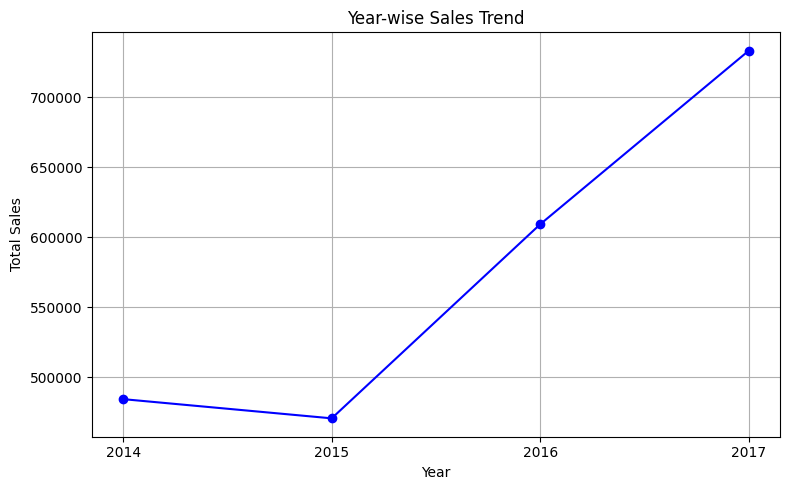

In [36]:
import matplotlib.pyplot as plt

yearly_sales.plot(
    kind="line",
    marker="o",
    color="blue",
    figsize=(8, 5)
)

plt.title("Year-wise Sales Trend")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.xticks(yearly_sales.index)
plt.grid(True)
plt.tight_layout()
plt.show()


In [37]:
# Day 3 - Step 17: Year-wise Profit Analysis

yearly_profit = (
    df.groupby("Year")["Profit"]
    .sum()
    .sort_index()
)

print("Year-wise Total Profit:\n")
print(yearly_profit.round(2))

Year-wise Total Profit:

Year
2014    49543.97
2015    61618.60
2016    81795.17
2017    93439.27
Name: Profit, dtype: float64


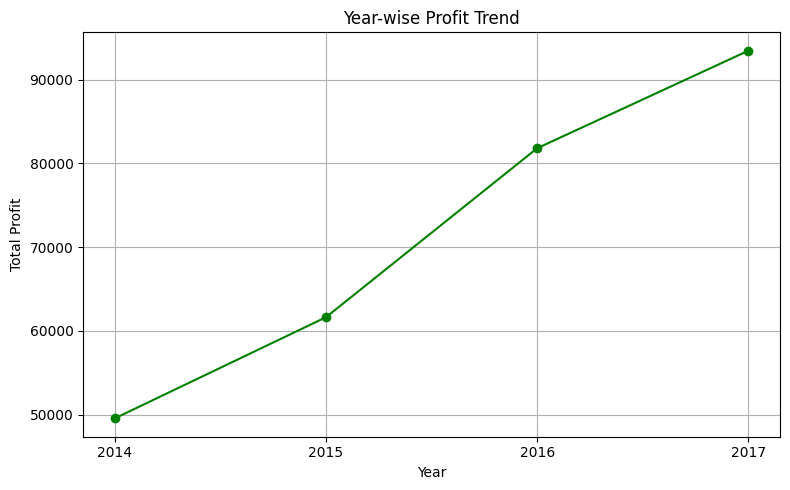

In [38]:
import matplotlib.pyplot as plt

yearly_profit.plot(
    kind="line",
    marker="o",
    color="green",
    figsize=(8, 5)
)

plt.title("Year-wise Profit Trend")
plt.xlabel("Year")
plt.ylabel("Total Profit")
plt.xticks(yearly_profit.index)
plt.grid(True)
plt.tight_layout()
plt.show()

In [39]:
# Day 3 - Step 19: Monthly Sales Analysis

monthly_sales = (
    df.groupby("Month")["Sales"]
    .sum()
    .sort_index()
)

print("Month-wise Total Sales:\n")
print(monthly_sales.round(2))

Month-wise Total Sales:

Month
1      94924.84
2      59751.25
3     205005.49
4     137762.13
5     155028.81
6     152718.68
7     147238.10
8     159044.06
9     307649.95
10    200322.98
11    352461.07
12    325293.50
Name: Sales, dtype: float64


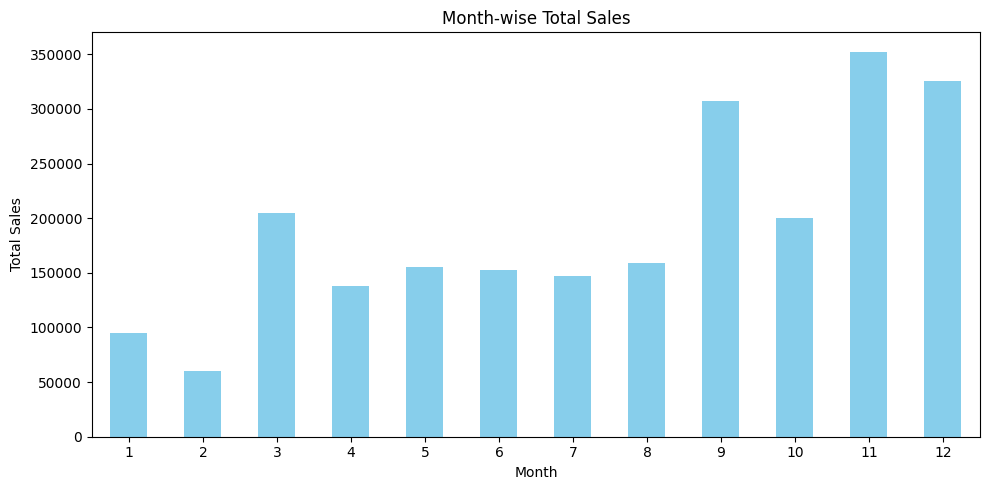

In [40]:
import matplotlib.pyplot as plt

monthly_sales.plot(
    kind="bar",
    color="skyblue",
    figsize=(10, 5)
)

plt.title("Month-wise Total Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [41]:
# Day 3 - Step 21: Monthly Profit Analysis

monthly_profit = (
    df.groupby("Month")["Profit"]
    .sum()
    .sort_index()
)

print("Month-wise Total Profit:\n")
print(monthly_profit.round(2))

Month-wise Total Profit:

Month
1      9134.45
2     10294.61
3     28594.69
4     11587.44
5     22411.31
6     21285.80
7     13832.66
8     21776.94
9     36857.48
10    31784.04
11    35468.43
12    43369.19
Name: Profit, dtype: float64


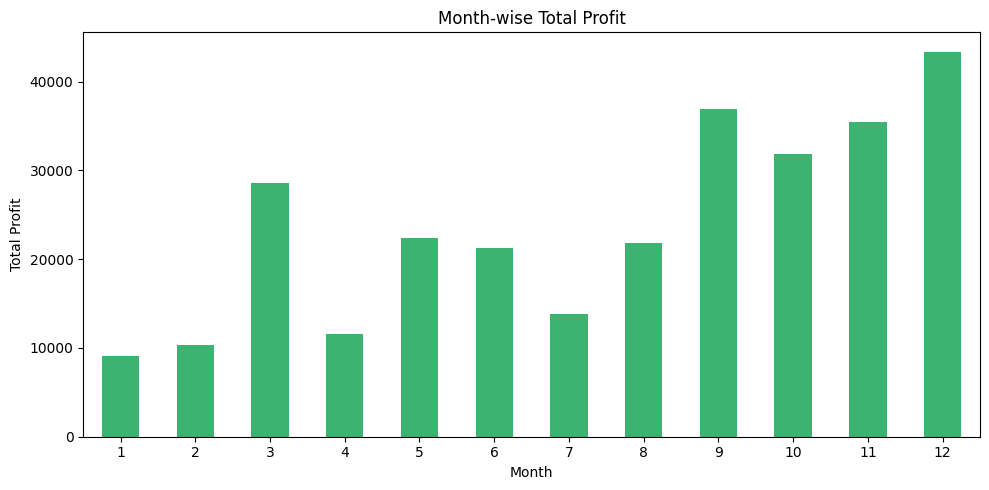

In [42]:
import matplotlib.pyplot as plt

monthly_profit.plot(
    kind="bar",
    color="mediumseagreen",
    figsize=(10, 5)
)

plt.title("Month-wise Total Profit")
plt.xlabel("Month")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [43]:
# Day 3 - Step 23: Category-wise Profit Margin

category_analysis["Profit_Margin"] = (
    category_analysis["Total_Profit"]
    / category_analysis["Total_Sales"]
) * 100

print("Category-wise Profit Margin:\n")

print(category_analysis[["Profit_Margin"]].round(2))

Category-wise Profit Margin:

                 Profit_Margin
Category                      
Furniture                 2.49
Office Supplies          17.04
Technology               17.40


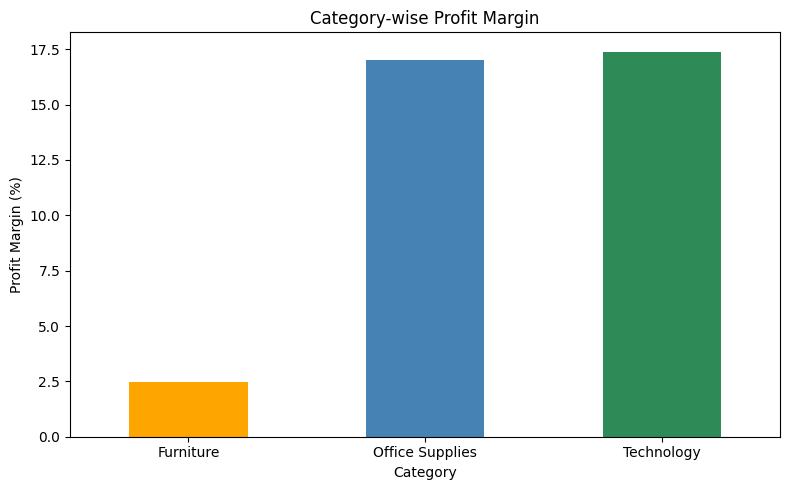

In [44]:
import matplotlib.pyplot as plt

category_analysis["Profit_Margin"].plot(
    kind="bar",
    color=["orange", "steelblue", "seagreen"],
    figsize=(8, 5)
)

plt.title("Category-wise Profit Margin")
plt.xlabel("Category")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [45]:
# Day 3 - Step 25: Analyse discounts on loss-making products

loss_product_details = df[df["Product Name"].isin(loss_products.index)]

print("Loss-Making Product Transactions:", len(loss_product_details))

print("\nAverage Discount on Loss-Making Products:")
print(round(loss_product_details["Discount"].mean() * 100, 2), "%")

print("\nAverage Profit on Loss-Making Product Transactions:")
print(round(loss_product_details["Profit"].mean(), 2))

print("\nAverage Sales on Loss-Making Product Transactions:")
print(round(loss_product_details["Sales"].mean(), 2))

Loss-Making Product Transactions: 1592

Average Discount on Loss-Making Products:
27.25 %

Average Profit on Loss-Making Product Transactions:
-48.41

Average Sales on Loss-Making Product Transactions:
348.88


In [46]:
# Compare loss-making and profit-making products

profit_product_details = df[
    df["Product Name"].isin(product_profit[product_profit > 0].index)
]

print("Loss-Making Products:")
print("Average Discount:",
      round(loss_product_details["Discount"].mean() * 100, 2), "%")
print("Average Profit:",
      round(loss_product_details["Profit"].mean(), 2))

print("\nProfit-Making Products:")
print("Average Discount:",
      round(profit_product_details["Discount"].mean() * 100, 2), "%")
print("Average Profit:",
      round(profit_product_details["Profit"].mean(), 2))

Loss-Making Products:
Average Discount: 27.25 %
Average Profit: -48.41

Profit-Making Products:
Average Discount: 13.41 %
Average Profit: 43.31


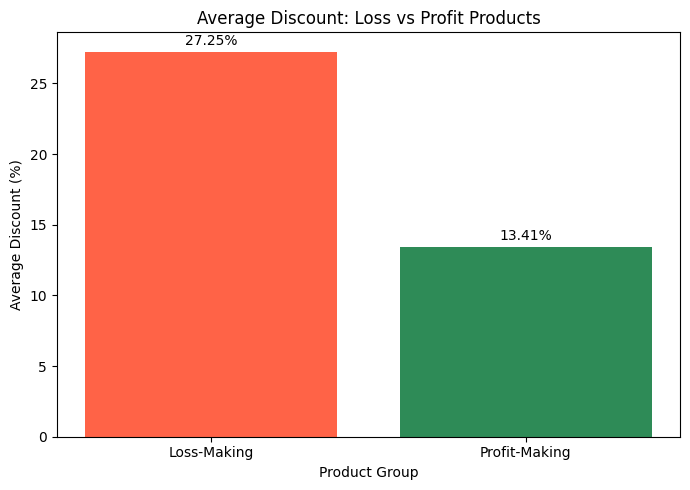

In [47]:
import matplotlib.pyplot as plt

discount_comparison = {
    "Loss-Making": loss_product_details["Discount"].mean() * 100,
    "Profit-Making": profit_product_details["Discount"].mean() * 100
}

plt.figure(figsize=(7, 5))
plt.bar(
    discount_comparison.keys(),
    discount_comparison.values(),
    color=["tomato", "seagreen"]
)

plt.title("Average Discount: Loss vs Profit Products")
plt.xlabel("Product Group")
plt.ylabel("Average Discount (%)")

for i, value in enumerate(discount_comparison.values()):
    plt.text(i, value + 0.5, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [48]:
# Day 3 - Step 28: Count loss-making products by category

loss_product_names = loss_products.index

loss_product_categories = (
    df[df["Product Name"].isin(loss_product_names)]
    .groupby("Category")["Product Name"]
    .nunique()
    .sort_values(ascending=False)
)

print("Loss-Making Products by Category:\n")
print(loss_product_categories)

Loss-Making Products by Category:

Category
Furniture          123
Office Supplies    122
Technology          56
Name: Product Name, dtype: int64


In [49]:
# Day 3 - Step 29: Total loss by category

loss_transactions = df[df["Profit"] < 0]

category_loss = (
    loss_transactions.groupby("Category")["Profit"]
    .sum()
    .sort_values()
)

print("Category-wise Total Loss:\n")
print(category_loss.round(2))

Category-wise Total Loss:

Category
Furniture         -60936.11
Office Supplies   -56615.26
Technology        -38579.92
Name: Profit, dtype: float64


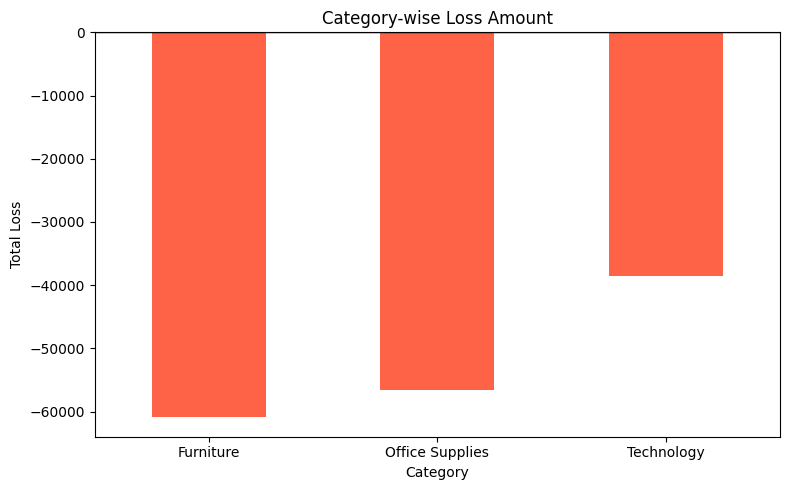

In [50]:
import matplotlib.pyplot as plt

category_loss.plot(
    kind="bar",
    color="tomato",
    figsize=(8, 5)
)

plt.title("Category-wise Loss Amount")
plt.xlabel("Category")
plt.ylabel("Total Loss")
plt.axhline(y=0, color="black", linewidth=1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [51]:
# Day 3 - Step 31: Final Findings Summary

print("=" * 45)
print("SALES AND PROFITABILITY ANALYSIS")
print("KEY FINDINGS")
print("=" * 45)

print("\n1. Overall Business Performance")
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Profit Margin:",
      round(df["Profit"].sum() / df["Sales"].sum() * 100, 2), "%")

print("\n2. Loss-Making Products")
print("Total Loss-Making Products:", len(loss_products))
print("Worst Product:", loss_products.index[0])
print("Highest Product Loss:", round(loss_products.iloc[0], 2))

print("\n3. Best Performing Category")
print(category_analysis["Total_Profit"].idxmax())

print("\n4. Lowest Profit Margin Category")
print(category_analysis["Profit_Margin"].idxmin())

print("\n5. Highest Sales Region")
print(region_sales.idxmax())

print("\n6. Highest Sales Year")
print(yearly_sales.idxmax())

print("\n7. Highest Sales Month")
print(monthly_sales.idxmax())

print("\n8. Loss-Making Sub-Categories")
print(loss_subcategories.index.tolist())

print("\n" + "=" * 45)
print("END OF FINDINGS")
print("=" * 45)

SALES AND PROFITABILITY ANALYSIS
KEY FINDINGS

1. Overall Business Performance
Total Sales: 2297200.86
Total Profit: 286397.02
Profit Margin: 12.47 %

2. Loss-Making Products
Total Loss-Making Products: 301
Worst Product: Cubify CubeX 3D Printer Double Head Print
Highest Product Loss: -8879.97

3. Best Performing Category
Technology

4. Lowest Profit Margin Category
Furniture

5. Highest Sales Region
West

6. Highest Sales Year
2017

7. Highest Sales Month
11

8. Loss-Making Sub-Categories
['Tables', 'Bookcases', 'Supplies']

END OF FINDINGS


In [52]:
print("PROJECT CONCLUSION")
print("-" * 35)

print("""
1. The business generated total sales of 2,297,200.86
   and total profit of 286,397.02.

2. The overall profit margin is 12.47%.

3. A total of 301 products were identified as
   loss-making based on their overall profit.

4. Technology is the best-performing category,
   while Furniture has the lowest profit margin.

5. Tables, Bookcases, and Supplies are
   loss-making sub-categories.

6. Loss-making product transactions have a higher
   average discount than profit-making products.

RECOMMENDATIONS
---------------
1. Review discount policies, especially high discounts.
2. Investigate loss-making products and sub-categories.
3. Review Furniture pricing and product costs.
4. Monitor profit margin along with total sales.
5. Track sales and profit trends regularly.
""")

PROJECT CONCLUSION
-----------------------------------

1. The business generated total sales of 2,297,200.86
   and total profit of 286,397.02.

2. The overall profit margin is 12.47%.

3. A total of 301 products were identified as
   loss-making based on their overall profit.

4. Technology is the best-performing category,
   while Furniture has the lowest profit margin.

5. Tables, Bookcases, and Supplies are
   loss-making sub-categories.

6. Loss-making product transactions have a higher
   average discount than profit-making products.

RECOMMENDATIONS
---------------
1. Review discount policies, especially high discounts.
2. Investigate loss-making products and sub-categories.
3. Review Furniture pricing and product costs.
4. Monitor profit margin along with total sales.
5. Track sales and profit trends regularly.



In [53]:
print("=" * 55)
print("SALES AND PROFITABILITY ANALYSIS USING PYTHON")
print("=" * 55)

print("\n1. PROJECT OBJECTIVE")
print("""
To analyse sales data using Python, identify loss-making
products, and understand factors affecting profitability.
""")

print("\n2. DATASET OVERVIEW")
print("Total Records:", len(df))
print("Total Columns:", len(df.columns))
print("Total Categories:", df["Category"].nunique())
print("Total Sub-Categories:", df["Sub-Category"].nunique())
print("Total Regions:", df["Region"].nunique())

print("\n3. PROJECT SUCCESS METRICS")
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Total Profit:", round(df["Profit"].sum(), 2))
print("Profit Margin:", round(
    df["Profit"].sum() / df["Sales"].sum() * 100, 2
), "%")
print("Loss-Making Products:", len(loss_products))

print("\n4. KEY FINDINGS")
print("Best Performing Category:",
      category_analysis["Total_Profit"].idxmax())
print("Lowest Profit Margin Category:",
      category_analysis["Profit_Margin"].idxmin())
print("Highest Sales Region:", region_sales.idxmax())
print("Highest Sales Year:", yearly_sales.idxmax())
print("Highest Sales Month:", monthly_sales.idxmax())

print("\n5. RECOMMENDATIONS")
print("""
1. Review high-discount transactions.
2. Investigate loss-making products.
3. Improve Furniture category profitability.
4. Monitor profit margins regularly.
5. Use sales trends for business planning.
""")

print("\n6. CONCLUSION")
print("""
The business is profitable overall, but some products
and sub-categories generate losses. Better discount
management and product-level analysis may help improve
profitability.
""")

print("=" * 55)
print("END OF PROJECT REPORT")
print("=" * 55)

SALES AND PROFITABILITY ANALYSIS USING PYTHON

1. PROJECT OBJECTIVE

To analyse sales data using Python, identify loss-making
products, and understand factors affecting profitability.


2. DATASET OVERVIEW
Total Records: 9994
Total Columns: 23
Total Categories: 3
Total Sub-Categories: 17
Total Regions: 4

3. PROJECT SUCCESS METRICS
Total Sales: 2297200.86
Total Profit: 286397.02
Profit Margin: 12.47 %
Loss-Making Products: 301

4. KEY FINDINGS
Best Performing Category: Technology
Lowest Profit Margin Category: Furniture
Highest Sales Region: West
Highest Sales Year: 2017
Highest Sales Month: 11

5. RECOMMENDATIONS

1. Review high-discount transactions.
2. Investigate loss-making products.
3. Improve Furniture category profitability.
4. Monitor profit margins regularly.
5. Use sales trends for business planning.


6. CONCLUSION

The business is profitable overall, but some products
and sub-categories generate losses. Better discount
management and product-level analysis may help improve